# Fanfiction Content of Archive Of Our Own F/F, M/M, and F/M Relationship Categories

## 1. Additional Tag Frequencies

### 1.1 Filtering the JSON Lines file

In [1]:
# Import packages
import statistics
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, OrderedDict
from scipy.stats import iqr

In [3]:
# Create the df_metadata DataFrame
df_metadata = pl.read_ndjson("./data/combined_metadata.jsonl")
df_metadata

id,title,metadata
str,str,struct[18]
"""16""","""Proximity""","{null,""Creator Chose Not To Use Archive Warnings"",""M/M"",""David Archuleta, David Cook"",null,""English"",""Teen And Up Audiences"",""Cook/Archuleta"",""by astolat"",""1/1"","""",""2008-09-13"",""2,482"",""American Idol RPF (Season 7)"",null,null,null,null}"
"""31""","""Pixiestix""","{""Kissing, commentfic, Bandslash"",""Creator Chose Not To Use Archive Warnings"",""Other"",""Mikey Way, Gerard Way, Frank Iero"",""My Chemical Romance, Six Degrees of Pete Wentz' dick"",""English"",""Not Rated"",""Mikey Way/Gerard Way"",""by zvi"",""1/1"","""",""2008-05-26"",""64"",null,null,null,null,null}"
"""175""","""Ghost in the Machine""","{""Artificial Intelligence, Mysticism, POV First Person"",""No Archive Warnings Apply"",""Gen"",null,null,""English"",""General Audiences"",null,""by juniperphoenix"",""1/1"","""",""2007-09-21"",""1,279"",""Quantum Leap"",""Ziggy (Quantum Leap)"",""Robots and artificial lifeforms"",null,null}"
"""150""","""Justin is the Verizon""","{""Crack Fic, Popslash - Freeform, Character of Color"",""Creator Chose Not To Use Archive Warnings"",""Other"",""Justin Timberlake, Nelly"",null,""English"",""Not Rated"",null,""by WitchQueen (zvi)"",""1/1"","""",""2002-07-16"",""250"",""NSYNC"",null,null,""Scenes from a Hat"",null}"
"""22""","""like a""","{""OT3, Songfic, Humor, Fluff, Character of Color, I Saw Three Ships"",""No Archive Warnings Apply"",""M/M"",""Rodney McKay, John Sheppard, Ronon Dex"",null,""English"",""Not Rated"",""John Sheppard/Rodney McKay/Ronon Dex"",""by zvi"",""1/1"","""",""2006-01-06"",""1,755"",""Stargate Atlantis"",null,null,null,null}"
…,…,…
"""9999911""","""Purgatory Oneshots""","{""Destiel - Freeform, Castiel/Dean Winchester in Purgatory, Purgatory, destiel one-shots, purgatory oneshots"",""Creator Chose Not To Use Archive Warnings"",""M/M"",""Castiel (Supernatural), Dean Winchester, Benny Lafitte"",null,""English"",""Mature"",""Castiel/Dean Winchester"",""by cirque_de_reves (orphan_account)"",""4/4"",""2017-04-11"",""2017-02-28"",""2,665"",""Supernatural"",null,null,null,null}"
"""9999959""","""Fork in the Road""","{""Soldier Enhancement Program, Soldier Enhancement Program Era, First Meetings, Internalized Homophobia, Snapshots, Friendship, Other Additional Tags to Be Added"",""No Archive Warnings Apply"",""Gen"",""Soldier: 76 | Jack Morrison, Reaper | Gabriel Reyes"",null,""English"",""Teen And Up Audiences"",""Soldier: 76 | Jack Morrison/Reaper | Gabriel Reyes"",""by Grimalkin"",""1/?"","""",""2017-02-28"",""1,559"",""Overwatch (Video Game)"",null,null,""I got my DNA rewritten at SEP and all I got was decades of gay chicken and this blown up Watchpoint"",null}"
"""9999935""","""Aftermath""","{""Angst, Tragedy, Romance"",""Major Character Death"",""M/M"",""Harry Potter, Severus Snape"",null,""English"",""Mature"",""Harry Potter/Severus Snape"",""by cnor9602 [archived by HPFandom_archivist]"",""1/1"","""",""2009-03-24"",""1,837"",""Harry Potter - J. K. Rowling"",null,""HPFandom"",null,null}"


In [4]:
# Turn the metadata column into 18 separate columns
df_metadata = df_metadata.unnest('metadata')
df_metadata

id,title,Additional Tags,Archive Warning,Category,Characters,Fandoms,Language,Rating,Relationship,author,chapters,completed,published,words,Fandom,Character,Collections,Series,Relationships
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""16""","""Proximity""",null,"""Creator Chose Not To Use Archi…","""M/M""","""David Archuleta, David Cook""",null,"""English""","""Teen And Up Audiences""","""Cook/Archuleta""","""by astolat""","""1/1""","""""","""2008-09-13""","""2,482""","""American Idol RPF (Season 7)""",null,null,null,null
"""31""","""Pixiestix""","""Kissing, commentfic, Bandslash""","""Creator Chose Not To Use Archi…","""Other""","""Mikey Way, Gerard Way, Frank I…","""My Chemical Romance, Six Degre…","""English""","""Not Rated""","""Mikey Way/Gerard Way""","""by zvi""","""1/1""","""""","""2008-05-26""","""64""",null,null,null,null,null
"""175""","""Ghost in the Machine""","""Artificial Intelligence, Mysti…","""No Archive Warnings Apply""","""Gen""",null,null,"""English""","""General Audiences""",null,"""by juniperphoenix""","""1/1""","""""","""2007-09-21""","""1,279""","""Quantum Leap""","""Ziggy (Quantum Leap)""","""Robots and artificial lifeform…",null,null
"""150""","""Justin is the Verizon""","""Crack Fic, Popslash - Freeform…","""Creator Chose Not To Use Archi…","""Other""","""Justin Timberlake, Nelly""",null,"""English""","""Not Rated""",null,"""by WitchQueen (zvi)""","""1/1""","""""","""2002-07-16""","""250""","""NSYNC""",null,null,"""Scenes from a Hat""",null
"""22""","""like a""","""OT3, Songfic, Humor, Fluff, Ch…","""No Archive Warnings Apply""","""M/M""","""Rodney McKay, John Sheppard, R…",null,"""English""","""Not Rated""","""John Sheppard/Rodney McKay/Ron…","""by zvi""","""1/1""","""""","""2006-01-06""","""1,755""","""Stargate Atlantis""",null,null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""9999911""","""Purgatory Oneshots""","""Destiel - Freeform, Castiel/De…","""Creator Chose Not To Use Archi…","""M/M""","""Castiel (Supernatural), Dean W…",null,"""English""","""Mature""","""Castiel/Dean Winchester""","""by cirque_de_reves (orphan_acc…","""4/4""","""2017-04-11""","""2017-02-28""","""2,665""","""Supernatural""",null,null,null,null
"""9999959""","""Fork in the Road""","""Soldier Enhancement Program, S…","""No Archive Warnings Apply""","""Gen""","""Soldier: 76 | Jack Morrison, R…",null,"""English""","""Teen And Up Audiences""","""Soldier: 76 | Jack Morrison/Re…","""by Grimalkin""","""1/?""","""""","""2017-02-28""","""1,559""","""Overwatch (Video Game)""",null,null,"""I got my DNA rewritten at SEP …",null
"""9999935""","""Aftermath""","""Angst, Tragedy, Romance""","""Major Character Death""","""M/M""","""Harry Potter, Severus Snape""",null,"""English""","""Mature""","""Harry Potter/Severus Snape""","""by cnor9602 [archived by HPFan…","""1/1""","""""","""2009-03-24""","""1,837""","""Harry Potter - J. K. Rowling""",null,"""HPFandom""",null,null


In [5]:
fandoms = ["DC's Legends of Tomorrow (TV)", "Avatar: The Last Airbender (Cartoon 2005)", "Spider-Man: Spider-Verse (Sony Animated Movies)"]
categories = ["F/F", "M/M", "F/M"]

# Select the target fandom and relationship categories
df_cats_and_fandoms = df_metadata.filter(
    ((pl.col("Fandom") == fandoms[0]) |
    (pl.col("Fandom") == fandoms[1]) |
    (pl.col("Fandom") == fandoms[2])) &
    ((pl.col("Category") == categories[0]) |
    (pl.col("Category") == categories[1]) |
    (pl.col("Category") == categories[2]))
)

df_cats_and_fandoms.head()

id,title,Additional Tags,Archive Warning,Category,Characters,Fandoms,Language,Rating,Relationship,author,chapters,completed,published,words,Fandom,Character,Collections,Series,Relationships
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""10012010""","""Just One Training""","""Explicit Sexual Content, Oral …","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""Explicit""","""Sara Lance/Leonard Snart""","""by capnwho""","""1/1""","""""","""2017-02-28""","""1,470""","""DC's Legends of Tomorrow (TV)""",null,null,"""Just One Fixation""",null
"""10013705""","""Five Months More""","""Established Relationship, surp…","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart""",null,"""English""","""Not Rated""",null,"""by flabbergabst""","""1/1""","""""","""2017-02-28""","""505""","""DC's Legends of Tomorrow (TV)""",null,null,"""The Captain Canary Collection""","""Sara Lance/Leonard Snart, Capt…"
"""10018964""","""It Ends with a Kiss""","""Alpha/Beta/Omega Dynamics, Min…","""No Archive Warnings Apply""","""M/M""","""Leonard Snart, Ray Palmer, Mic…",null,"""English""","""Teen And Up Audiences""","""Ray Palmer/Leonard Snart""","""by Constantsnow""","""1/1""","""""","""2017-02-28""","""3,008""","""DC's Legends of Tomorrow (TV)""",null,null,null,null
"""10030784""","""Bet""",null,"""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""General Audiences""","""Sara Lance/Leonard Snart""","""by orphan_account""","""1/1""","""""","""2017-03-01""","""1,273""","""DC's Legends of Tomorrow (TV)""",null,null,null,null
"""10033958""","""For the Both of Us""","""Captain Canary, ficcingcaptain…","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""Not Rated""",null,"""by flabbergabst""","""1/1""","""""","""2017-03-01""","""1,067""","""DC's Legends of Tomorrow (TV)""",null,null,"""The Captain Canary Collection""","""Sara Lance/Leonard Snart, Capt…"


In [6]:
# Count the amount of fan works per fandom and category composition
i = 0
for fandom in fandoms:
    j = 0
    for category in categories:
        print(f"{fandoms[i]} | {categories[j]}:", df_cats_and_fandoms.filter(
            (pl.col("Category") == categories[j]) &
            (pl.col("Fandom") == fandoms[i])
        ).select(pl.len()))
        j += 1
    i += 1

DC's Legends of Tomorrow (TV) | F/F: shape: (1, 1)
┌──────┐
│ len  │
│ ---  │
│ u32  │
╞══════╡
│ 1574 │
└──────┘
DC's Legends of Tomorrow (TV) | M/M: shape: (1, 1)
┌──────┐
│ len  │
│ ---  │
│ u32  │
╞══════╡
│ 1263 │
└──────┘
DC's Legends of Tomorrow (TV) | F/M: shape: (1, 1)
┌──────┐
│ len  │
│ ---  │
│ u32  │
╞══════╡
│ 1619 │
└──────┘
Avatar: The Last Airbender (Cartoon 2005) | F/F: shape: (1, 1)
┌─────┐
│ len │
│ --- │
│ u32 │
╞═════╡
│ 373 │
└─────┘
Avatar: The Last Airbender (Cartoon 2005) | M/M: shape: (1, 1)
┌─────┐
│ len │
│ --- │
│ u32 │
╞═════╡
│ 599 │
└─────┘
Avatar: The Last Airbender (Cartoon 2005) | F/M: shape: (1, 1)
┌──────┐
│ len  │
│ ---  │
│ u32  │
╞══════╡
│ 1039 │
└──────┘
Spider-Man: Spider-Verse (Sony Animated Movies) | F/F: shape: (1, 1)
┌─────┐
│ len │
│ --- │
│ u32 │
╞═════╡
│ 81  │
└─────┘
Spider-Man: Spider-Verse (Sony Animated Movies) | M/M: shape: (1, 1)
┌──────┐
│ len  │
│ ---  │
│ u32  │
╞══════╡
│ 1823 │
└──────┘
Spider-Man: Spider-Verse (Sony Animat

### 1.2 Creating the DataFrames

#### 1.2.1 Creating the df_main DataFrame

In [7]:
def create_temp_df(fandom, category):
    """
    Creates a DataFrame of the additional tags frequencies.

    Parameters:
        fandom (string): Target fandom.
        category (string): Target relationship category.
    returns:
        df_temp (DataFrame): Consisting of Fandom, Category, Additional Tags, and Freq columns.
    """
    # Filter the df_cats_and_fandoms DataFrame based on the target fandom and category
    df_filtered = df_cats_and_fandoms.filter(
        (pl.col("Fandom") == fandom) &
        (pl.col("Category") == category)
    ).with_row_index()

    # Convert the Additional Tags column from a string to a list of strings
    df_filtered = df_filtered.with_columns(
        pl.col("Additional Tags").str.split(", "),
    )
    
    tags_freq = {}
    for row in df_filtered.iter_rows(named=True):
        try:
            for tag in row["Additional Tags"]:
                # Check if the Additional Tags key exists
                if tag not in tags_freq:
                    # Create the Additional Tags key
                    tags_freq[tag] = 0
                # Increase the Additional Tags frequency count with 1
                tags_freq[tag] += 1
        except:
            pass

    # Sort the tags_freq dictionary based on descending additional tag frequency order
    tags_freq = dict(sorted(tags_freq.items(), key=lambda item: item[1], reverse=True))

    # Create a DataFrame
    df_temp = pl.DataFrame({
        "Fandom": fandom,
        "Category": category,
        "Additional Tags": tags_freq.keys(),
        "Freq": tags_freq.values()
    })

    return df_temp

In [8]:
df_main = pl.DataFrame()
for fandom in fandoms:
    for category in categories:
        # Concatenate the temporary DataFrame to df_main
        df_main = pl.concat([df_main, create_temp_df(fandom, category)])

df_main

Fandom,Category,Additional Tags,Freq
str,str,str,i64
"""DC's Legends of Tomorrow (TV)""","""F/F""","""Fluff""",284
"""DC's Legends of Tomorrow (TV)""","""F/F""","""Angst""",150
"""DC's Legends of Tomorrow (TV)""","""F/F""","""AvaLance""",132
"""DC's Legends of Tomorrow (TV)""","""F/F""","""Hurt/Comfort""",108
"""DC's Legends of Tomorrow (TV)""","""F/F""","""Angst with a Happy Ending""",68
…,…,…,…
"""Spider-Man: Spider-Verse (Sony…","""F/M""","""Miles Morales is smitten""",1
"""Spider-Man: Spider-Verse (Sony…","""F/M""","""y/n cries""",1
"""Spider-Man: Spider-Verse (Sony…","""F/M""","""texting while fighting""",1


In [9]:
# Save the df_main DataFrame as a CSV file
df_main.write_csv('./data/df_additional_tags.csv')

#### 1.2.2 Creating the df_unique DataFrame

In [ ]:
df_unique = df_main.unique(subset='Additional Tags', keep='first', maintain_order=True) # Create a DataFrame of the unique values in the Additional Tags column
df_unique = df_unique.drop(["Fandom", "Category", "Freq"]) # Drop the Fandom, Category, and Freq columns
df_unique.write_csv('./data/df_unique.csv') # Save the df_unique DataFrame as a CSV file

### 1.3 Creating Additional Tag-Frequency Dictionaries

In [11]:
def count_dict(tags):
    """
    Counts the frequencies of the additional tags.

    Parameter:
        tags (DataFrame): Consists of additional tags and their frequencies.
    Returns:
        tags_dict (Dictionary): Contains the Additional Tags and Freq as a key-value pair.
    """
    tags_dict = {}
    for row in tags.iter_rows(named=True):
        # Check if the Additional Tags key exists
        if row["Additional Tags"] not in tags_dict:
            # Create the Additional Tags key
            tags_dict[row["Additional Tags"]] = 0
        # Add the current frequency to the Additional Tags frequency count
        tags_dict[row["Additional Tags"]] += row["Freq"]

    return Counter(tags_dict)

def one_filter(df, column, value):
    """
    Filters the Target DataFrame.

    Parameters:
        df (DataFrame): Target DataFrame.
        column (String): Target column.
        value (String): Column value.
    Returns:
        tags_dict (Dictionary): Contains the Additional Tags and Freq as key-value pair.
    """
    df_all_cats_1_fandom = df.filter(
        pl.col(column) == value # Filters a specific column based on a target value
    ).select(["Additional Tags", "Freq"]) # Selects the Additional Tags and Frequency columns

    return count_dict(df_all_cats_1_fandom)

def one_cat_1_fandom(df, category, fandom):
    """
    Filters the Target DataFrame.

    Parameters:
        df (DataFrame): Target DataFrame.
        category (String): Target relationship category.
        fandom (String): Target fandom.
    Returns:
        tags_dict (Dictionary): Contains the Additional Tags and Freq as key-value pair.
    """
    df_1_cat_1_fandom = df.filter(
        (pl.col("Category") == category) & # Filters the Category column based on a target category
        (pl.col("Fandom") == fandom) # Filters the Fandom column based on a target fandom
    ).select(["Additional Tags", "Freq"]) # Selects the Additional Tags and Frequency columns
    
    return count_dict(df_1_cat_1_fandom)

In [12]:
# Count all additional tags filtered by F/F + M/M + F/M categories of all fandoms combined
df_all = df_main.select(["Additional Tags", "Freq"]) # Selects the Additional Tags and Frequency columns
all_dict = count_dict(df_all)

# Count all additional tags filtered by 1 category of all fandoms combined
all_fandoms_ff_dict = one_filter(df_main, "Category", categories[0]) # all fandoms, F/F category
all_fandoms_mm_dict = one_filter(df_main, "Category", categories[1]) # all fandoms, M/M category
all_fandoms_fm_dict = one_filter(df_main, "Category", categories[2]) # all fandoms, F/M category

# Count all additional tags filtered by F/F + MM of all fandoms combined
all_fandoms_ff_mm_dict = all_fandoms_ff_dict + all_fandoms_mm_dict

# Count all additional tags filtered by F/F + M/M + F/M categories of 1 fandom
all_cats_lot_dict = one_filter(df_main, "Fandom", fandoms[0]) # LoT, all categories
all_cats_avatar_dict = one_filter(df_main, "Fandom", fandoms[1]) # Avatar, all categories
all_cats_spider_man_dict = one_filter(df_main, "Fandom", fandoms[2]) # Spider-Man, all categories

# Count all additional tags filtered by 1 category of 1 fandom
ff_lot_dict = one_cat_1_fandom(df_main, categories[0], fandoms[0]) # LoT, F/F category
mm_lot_dict = one_cat_1_fandom(df_main, categories[1], fandoms[0]) # LoT, M/M category
fm_lot_dict = one_cat_1_fandom(df_main, categories[2], fandoms[0]) # LoT, F/M category
ff_avatar_dict = one_cat_1_fandom(df_main, categories[0], fandoms[1]) # Avatar, F/F category
mm_avatar_dict = one_cat_1_fandom(df_main, categories[1], fandoms[1]) # Avatar, M/M category
fm_avatar_dict = one_cat_1_fandom(df_main, categories[2], fandoms[1]) # Avatar, F/M category
ff_spider_man_dict = one_cat_1_fandom(df_main, categories[0], fandoms[2]) # Spider-Man, F/F category
mm_spider_man_dict = one_cat_1_fandom(df_main, categories[1], fandoms[2]) # Spider-Man, M/M category
fm_spider_man_dict = one_cat_1_fandom(df_main, categories[2], fandoms[2]) # Spider-Man, F/M category

# Count all additional tags filtered by F/F + M/M categories of 1 fandom
ff_mm_lot_dict = ff_lot_dict + mm_lot_dict # LoT, F/F + M/M
ff_mm_avatar_dict = ff_avatar_dict + mm_avatar_dict # Avatar, F/F + M/M
ff_mm_spider_man_dict = ff_spider_man_dict + mm_spider_man_dict # Spider-Man, F/F + M/M

# Count all additional tags filtered by LoT + Avatar
ff_lot_avatar_dict = ff_lot_dict + ff_avatar_dict # LoT + Avatar, F/F
mm_lot_avatar_dict = mm_lot_dict + mm_avatar_dict # LoT + Avatar, M/M
fm_lot_avatar_dict = fm_lot_dict + fm_avatar_dict # LoT + Avatar, F/M
ff_mm_lot_avatar_dict = ff_lot_avatar_dict + mm_lot_avatar_dict # LoT + Avatar, F/F + M/M
lot_avatar_dict = ff_mm_lot_dict + ff_mm_avatar_dict + fm_lot_avatar_dict  # LoT + Avatar, all categories

# Count all the additiona tags filterd by Avatar

main_dict = {
    "All Fandoms and Categories": all_dict,
    "All Fandoms F/F": all_fandoms_ff_dict,
    "All Fandoms M/M": all_fandoms_mm_dict,
    "All Fandoms F/M": all_fandoms_fm_dict,
    "All Fandoms F/F + M/M": all_fandoms_ff_mm_dict,
    "LoT All Categories": all_cats_lot_dict,
    "Avatar All Categories": all_cats_avatar_dict,
    "Spider-Man All Categories": all_cats_spider_man_dict,
    "LoT F/F": ff_lot_dict,
    "LoT M/M": mm_lot_dict,
    "LoT F/M": fm_lot_dict,
    "Avatar F/F": ff_avatar_dict,
    "Avatar M/M": mm_avatar_dict,
    "Avatar F/M": fm_avatar_dict,
    "Spider-Man F/F": ff_spider_man_dict,
    "Spider-Man M/M": mm_spider_man_dict,
    "Spider-Man F/M": fm_spider_man_dict,
    "LoT F/F + M/M": ff_mm_lot_dict,
    "Avatar F/F + M/M": ff_mm_avatar_dict,
    "Spider-Man F/F + M/M": ff_mm_spider_man_dict,
    "LoT + Avatar All Categories": lot_avatar_dict,
    "LoT + Avatar F/F": ff_lot_avatar_dict,
    "LoT + Avatar M/M": mm_lot_avatar_dict,
    "LoT + Avatar F/M": fm_lot_avatar_dict,
    "LoT + Avatar F/F + M/M": ff_mm_lot_avatar_dict
}

print("DICTIONARY LENGTH")
dict_names = []
dict_length = []
for k, v in main_dict.items():
    dict_names.append(k)
    # Calculate the amount of unique Additional Tags
    length = len(v)
    dict_length.append(length)
    print(f"{k}: {length}")

DICTIONARY LENGTH
All Fandoms and Categories: 25908
All Fandoms F/F: 5424
All Fandoms M/M: 12667
All Fandoms F/M: 12150
All Fandoms F/F + M/M: 16701
LoT All Categories: 8827
Avatar All Categories: 7616
Spider-Man All Categories: 12770
LoT F/F: 3556
LoT M/M: 3782
LoT F/M: 2818
Avatar F/F: 1830
Avatar M/M: 3336
Avatar F/M: 4138
Spider-Man F/F: 617
Spider-Man M/M: 7230
Spider-Man F/M: 6886
LoT F/F + M/M: 6775
Avatar F/F + M/M: 4611
Spider-Man F/F + M/M: 7550
LoT + Avatar All Categories: 15198
LoT + Avatar F/F: 5021
LoT + Avatar M/M: 6565
LoT + Avatar F/M: 6425
LoT + Avatar F/F + M/M: 10529


### 1.4 Visualizing Additional Tag-Frequency Dictionaries

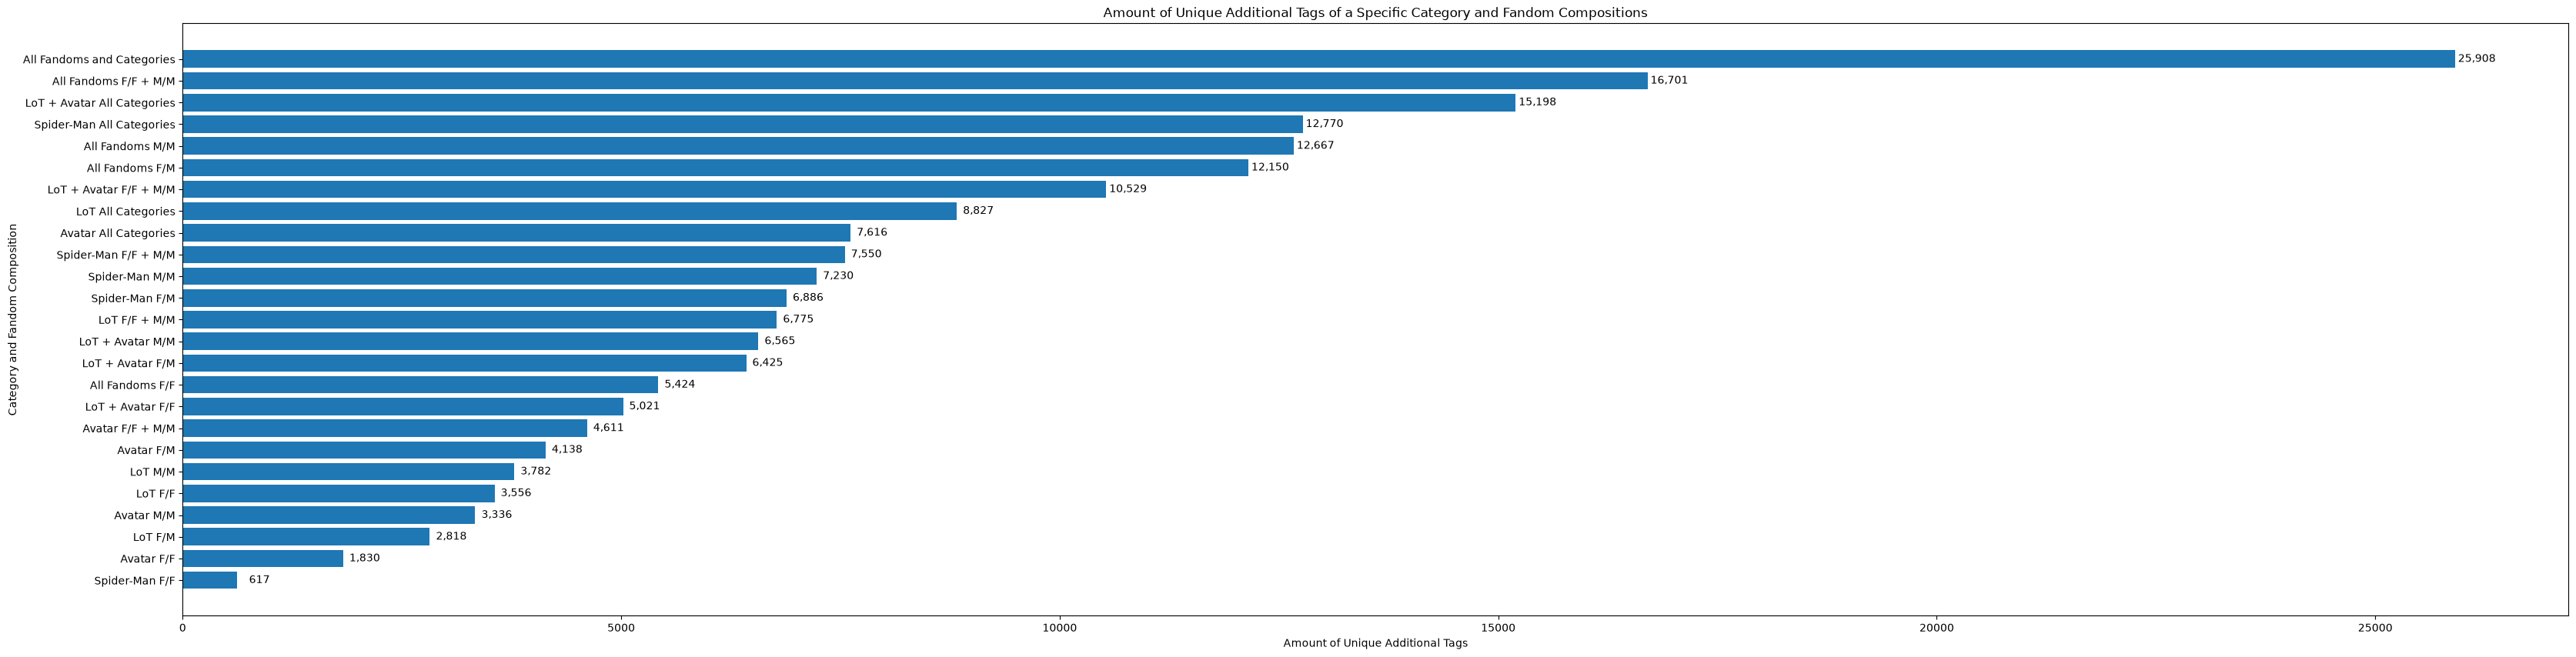

In [13]:
df_dict_lengths = pl.DataFrame({"Dictionary Name": dict_names, "Length": dict_length})
df_dict_lengths = df_dict_lengths.sort("Length")

# Plot a horizontal bar plot of the amount of additional tags
fig, ax = plt.subplots(figsize=(40, 10))
bar_container = ax.barh(df_dict_lengths["Dictionary Name"], df_dict_lengths["Length"])
ax.tick_params(axis='x', labelrotation=0)
ax.set(ylabel="Category and Fandom Composition", xlabel="Amount of Unique Additional Tags", title="Amount of Unique Additional Tags of a Specific Category and Fandom Compositions")
ax.bar_label(bar_container, fmt='{:7,.0f}', rotation=0)
plt.show()

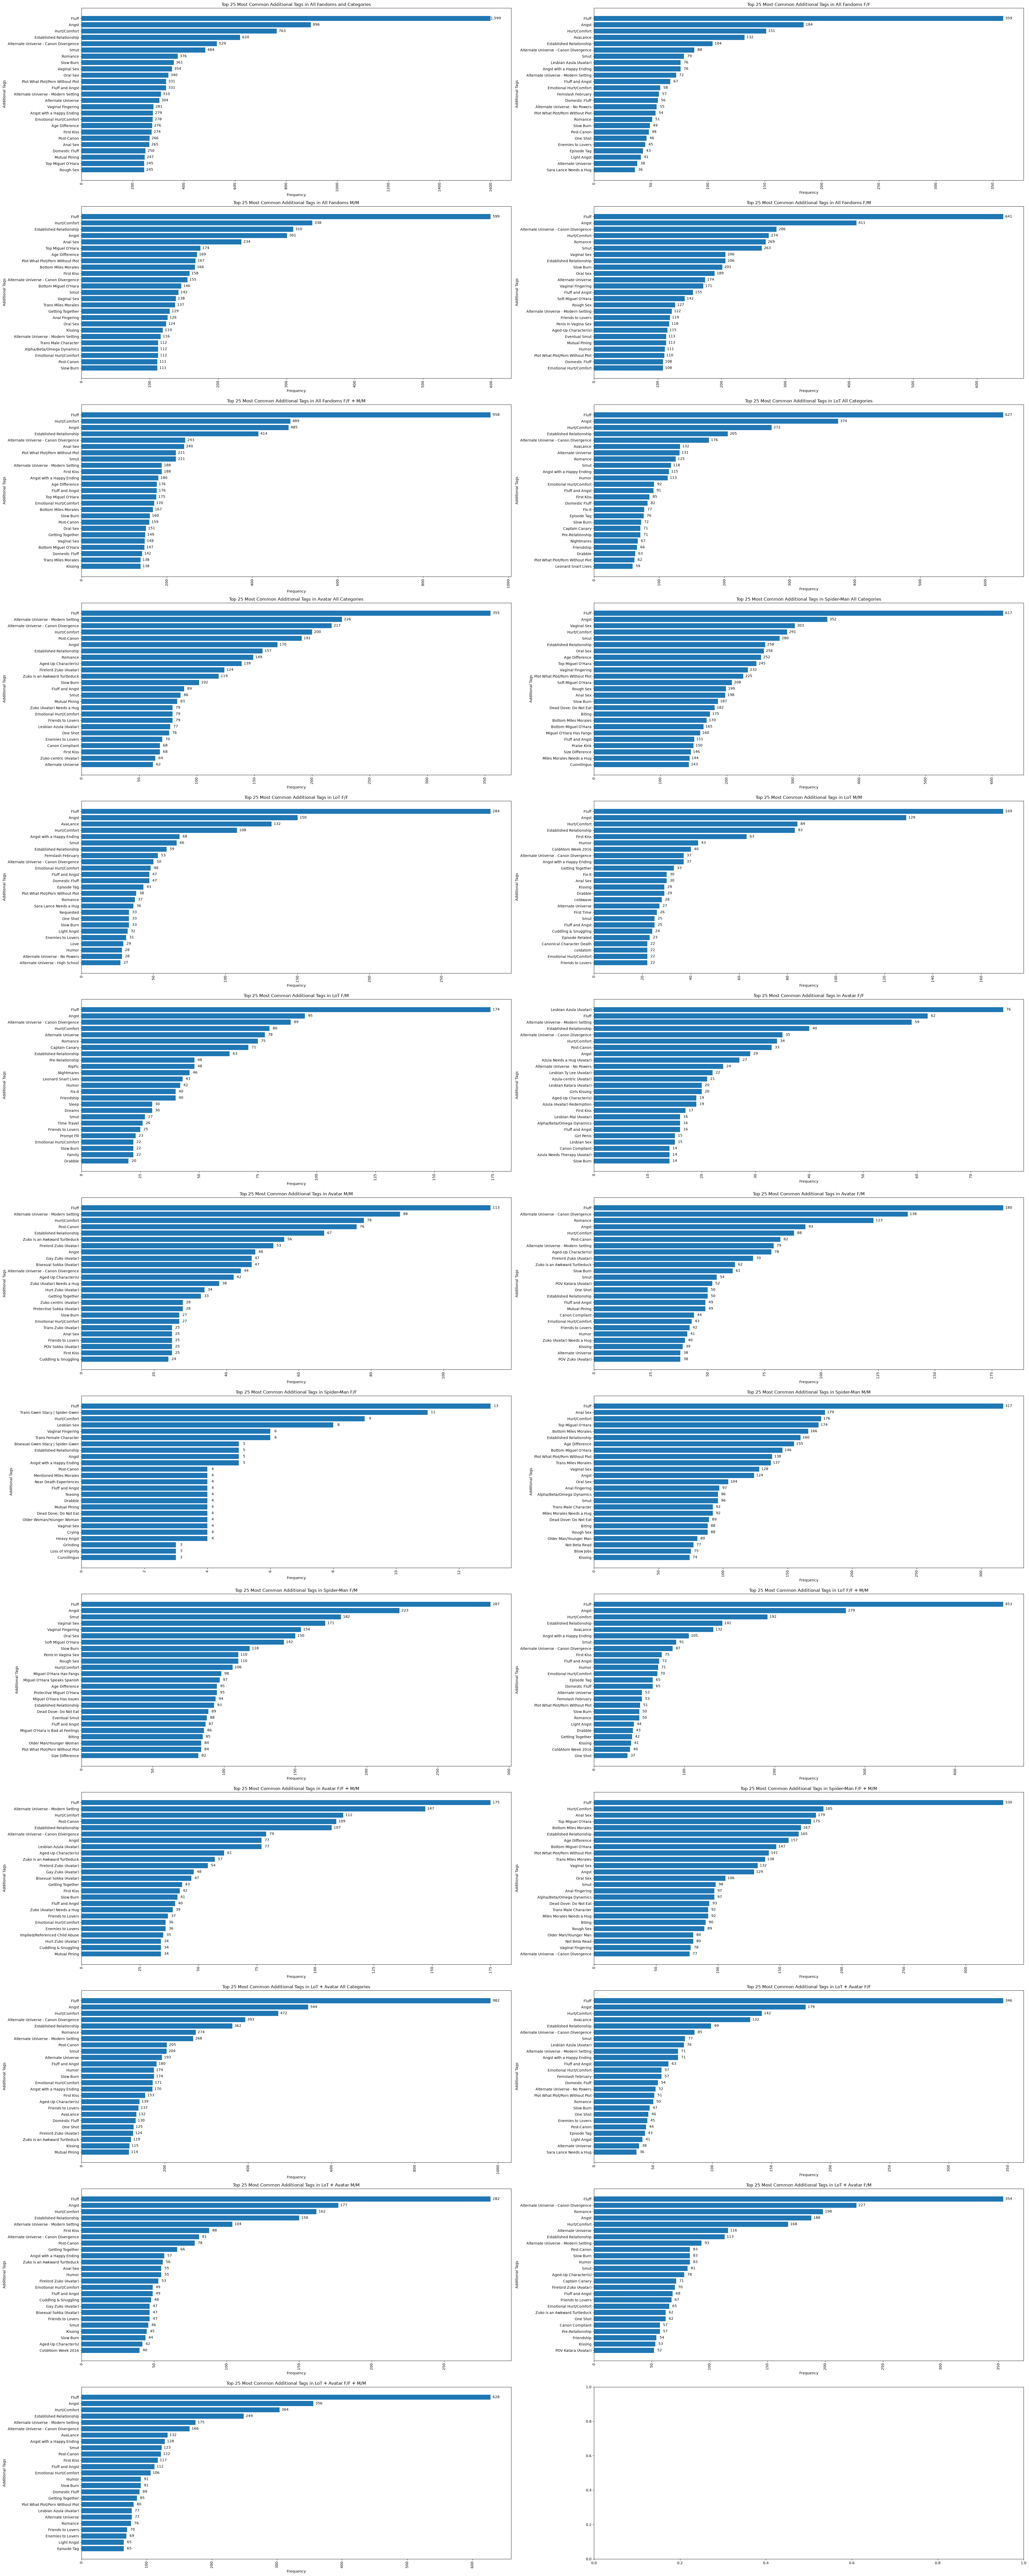

In [14]:
# Plot horizontal bar plots of the top 25 most common additional tags
fig, ax = plt.subplots(13, 2, figsize=(40,100))
row = 0
col = 0
# Loop over keys in the dictionary
for file in main_dict:
    # Turn the 25 most common additional tags of a specific key into a dictionary
    tag_freq = dict(main_dict[file].most_common(25))
    # Sort the dictionary in ascensing order
    tag_freq = OrderedDict(sorted(tag_freq.items(), key=lambda item: item[1]))
    # Turn the additional tags into a list
    additional_tags = list(tag_freq.keys())
    # Turn the frequencies into a list
    freq = list(tag_freq.values())

    # Plot a horizontal bar plot
    bar_container = ax[row, col].barh(additional_tags, freq)
    ax[row, col].tick_params(axis='x', labelrotation=90)
    ax[row, col].set(ylabel='Additional Tags', xlabel='Frequency', title=f'Top 25 Most Common Additional Tags in {file}')
    ax[row, col].bar_label(bar_container, fmt='{:5,.0f}', rotation=0)

    # Check where the bar plot is going to be plotted
    if col < 1:
        col += 1
    elif (col == 1) and (row < 12):
        row += 1
        col = 0

plt.tight_layout()
plt.show()

## 2. Descriptive Statistics

### 2.1 Calculating Descriptive Statistics

In [15]:
means = []
mins = []
ranges = []
dict_of_lists = {}
amt_of_keys = len(main_dict) - 1
index = 0
# Create a DataFrame
df_descriptive_stats = pl.DataFrame()
for k, v in main_dict.items():
    values = list(v.values())
    dict_of_lists.update({k: values})

    # Calculate the amount of Unique Additional Tags
    length_of_dict = len(v)

    # Calculate measures of centrality
    mean = np.mean(values) # Calculate the mean
    means.append(mean)
    median = np.median(values) # Calculate the median
    mode = statistics.mode(values) # Calculate the mode

    # Calculate measures of variability
    maximum = max(values)
    minimum = min(values)
    mins.append(minimum)
    r = maximum - minimum # Calculate the range
    ranges.append(r)
    variance = statistics.variance(values) # Calculate the variance
    standard_dev = statistics.stdev(values) # Calculate the standard deviation

    q1 = np.percentile(values, 25)
    q2 = np.percentile(values, 50)
    q3 = np.percentile(values, 75)
    interquartile_range = iqr(values) # Calculate the interquartile range
    quartile_deviation = interquartile_range / 2 # Calcualte Quartile Deviation

    # Create a temporary DataFrame
    df_temp_descriptive_stats = pl.DataFrame({
        "Categories and Fandoms": k,
        "Amount of Unique Additional Tags": length_of_dict,
        "Mean (Additional Tags Freq)": mean,
        "Median (Additional Tags Freq)": median,
        "Mode (Additional Tags Freq)": mode,
        "Minimum (Additional Tags Freq)": minimum,
        "Maximum (Additional Tags Freq)": maximum,
        "Range (Additional Tags Freq)": r,
        "Variance (Additional Tags Freq)": variance,
        "Standard Deviation (Additional Tags Freq)": standard_dev,
        "Q1 (Additional Tags Freq)": q1,
        "Q2 (Additional Tags Freq)": q2,
        "Q3 (Additional Tags Freq)": q3,
        "Interquartile Range (Additional Tags Freq)": interquartile_range,
        "Quartile Deviation (Additional Tags Freq)": quartile_deviation,
    })
    # Concatenate the temporary DataFrame to df_descriptive_stats
    df_descriptive_stats = pl.concat([df_descriptive_stats, df_temp_descriptive_stats])

    print(f"""{k}:

Measures of Centrality:
Mean: {mean}
Median: {median}
Mode: {mode}

Measures of Variability:
Minimum: {minimum}
Maximum: {maximum}
Range: {r}
Variance: {variance}
Standard Deviation: {standard_dev}
Lower Quartile: {q1}
Middle Quartile: {q2}
Upper Quartile: {q3}
Interquartile Range: {interquartile_range}
Quartile Deviation: {quartile_deviation}""")
    if index < amt_of_keys:
        print("""
~~~
""")
    index += 1

df_descriptive_stats

All Fandoms and Categories:

Measures of Centrality:
Mean: 3.199397869383974
Median: 1.0
Mode: 1

Measures of Variability:
Minimum: 1
Maximum: 1599
Range: 1598
Variance: 351.255332945025
Standard Deviation: 18.74180708856606
Lower Quartile: 1.0
Middle Quartile: 1.0
Upper Quartile: 1.0
Interquartile Range: 0.0
Quartile Deviation: 0.0

~~~

All Fandoms F/F:

Measures of Centrality:
Mean: 2.1441740412979353
Median: 1.0
Mode: 1

Measures of Variability:
Minimum: 1
Maximum: 359
Range: 358
Variance: 58.14664501193159
Standard Deviation: 7.625394744662835
Lower Quartile: 1.0
Middle Quartile: 1.0
Upper Quartile: 1.0
Interquartile Range: 0.0
Quartile Deviation: 0.0

~~~

All Fandoms M/M:

Measures of Centrality:
Mean: 2.8122680982079418
Median: 1.0
Mode: 1

Measures of Variability:
Minimum: 1
Maximum: 599
Range: 598
Variance: 127.5219938052691
Standard Deviation: 11.292563650707004
Lower Quartile: 1.0
Middle Quartile: 1.0
Upper Quartile: 1.0
Interquartile Range: 0.0
Quartile Deviation: 0.0

~~~

Categories and Fandoms,Amount of Unique Additional Tags,Mean (Additional Tags Freq),Median (Additional Tags Freq),Mode (Additional Tags Freq),Minimum (Additional Tags Freq),Maximum (Additional Tags Freq),Range (Additional Tags Freq),Variance (Additional Tags Freq),Standard Deviation (Additional Tags Freq),Q1 (Additional Tags Freq),Q2 (Additional Tags Freq),Q3 (Additional Tags Freq),Interquartile Range (Additional Tags Freq),Quartile Deviation (Additional Tags Freq)
str,i64,f64,f64,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64
"""All Fandoms and Categories""",25908,3.199398,1.0,1,1,1599,1598,351.255333,18.741807,1.0,1.0,1.0,0.0,0.0
"""All Fandoms F/F""",5424,2.144174,1.0,1,1,359,358,58.146645,7.625395,1.0,1.0,1.0,0.0,0.0
"""All Fandoms M/M""",12667,2.812268,1.0,1,1,599,598,127.521994,11.292564,1.0,1.0,1.0,0.0,0.0
"""All Fandoms F/M""",12150,2.933086,1.0,1,1,641,640,149.222701,12.215674,1.0,1.0,1.0,0.0,0.0
"""All Fandoms F/F + M/M""",16701,2.829352,1.0,1,1,958,957,182.433273,13.506786,1.0,1.0,1.0,0.0,0.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""LoT + Avatar All Categories""",15198,2.678642,1.0,1,1,982,981,185.87685,13.633666,1.0,1.0,1.0,0.0,0.0
"""LoT + Avatar F/F""",5021,2.151763,1.0,1,1,346,345,58.291705,7.6349,1.0,1.0,1.0,0.0,0.0
"""LoT + Avatar M/M""",6565,2.136786,1.0,1,1,282,281,43.580312,6.601539,1.0,1.0,1.0,0.0,0.0


### 2.2 Visualizing Descriptive Statistics

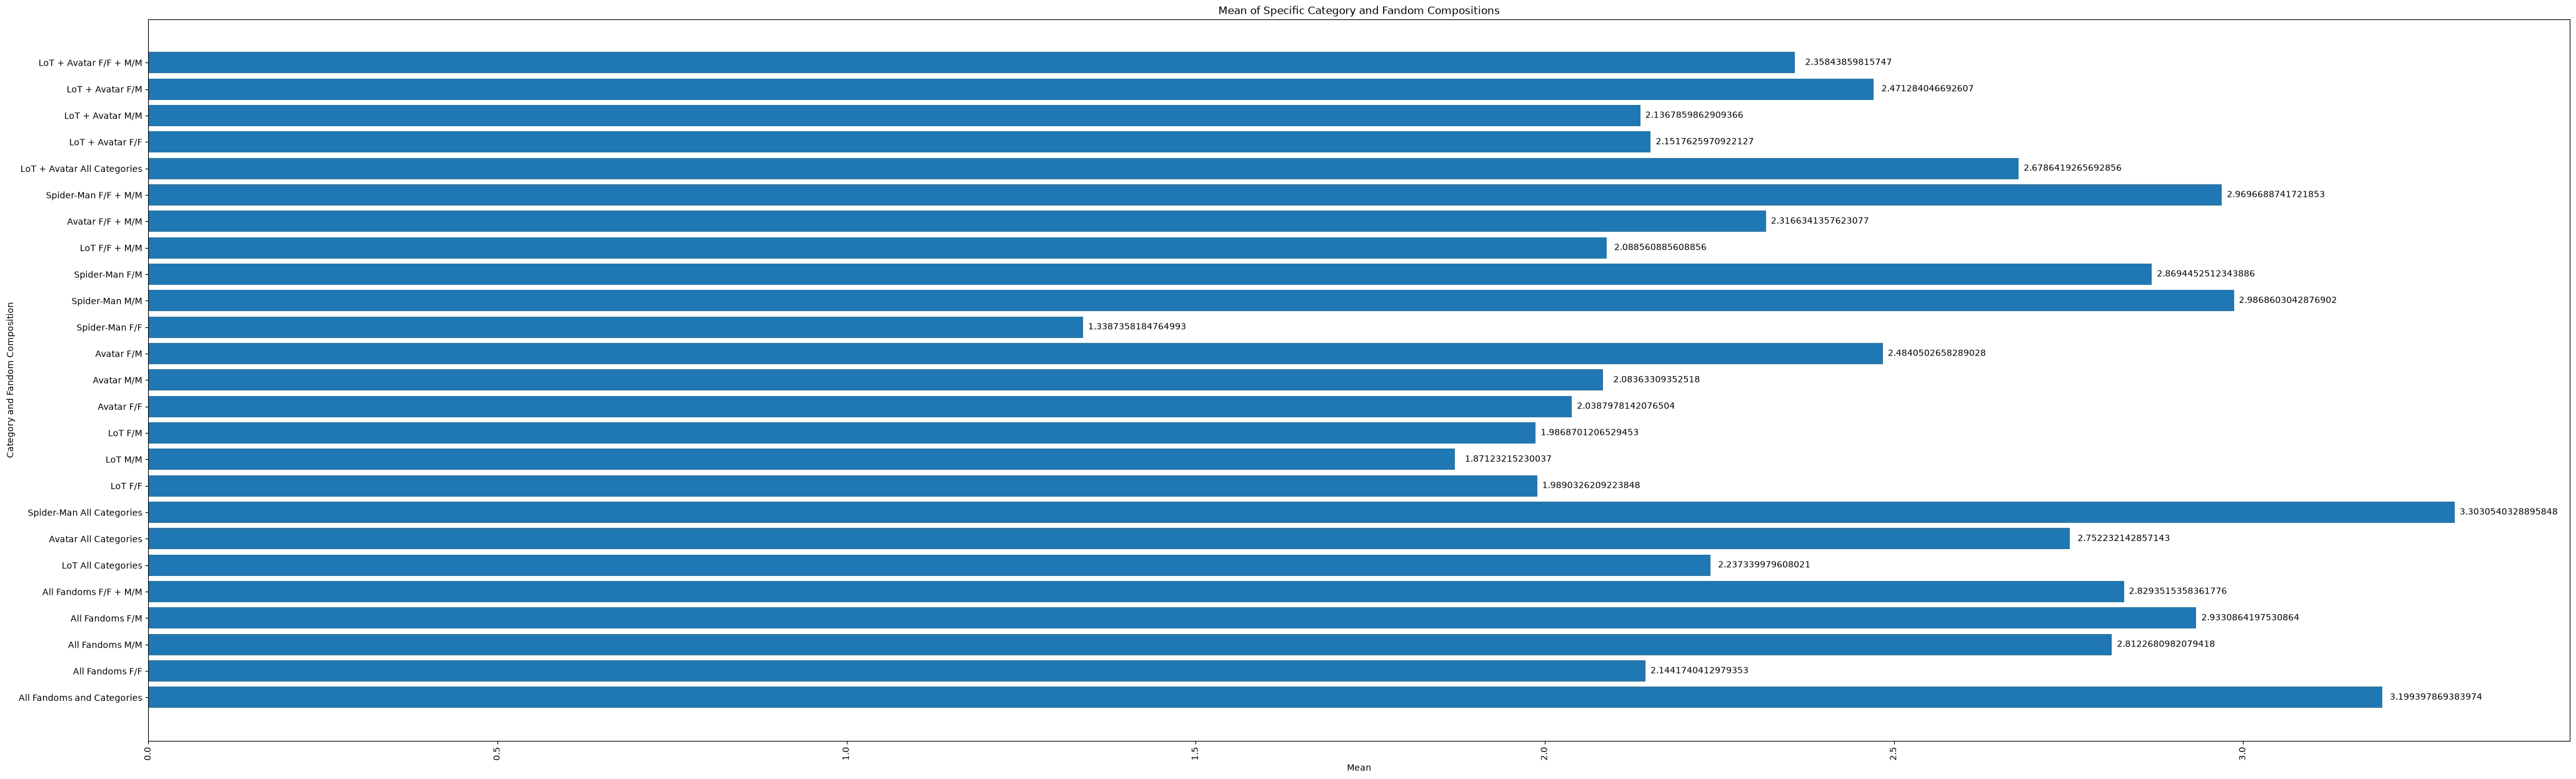

In [16]:
# Plot a horizontal bar plot of the mean
fig, ax = plt.subplots(figsize=(50, 15))
bar_container = ax.barh(dict_names, means)
ax.tick_params(axis='x', labelrotation=90)
ax.set(ylabel='Category and Fandom Composition', xlabel='Mean', title='Mean of Specific Category and Fandom Compositions')
ax.bar_label(bar_container, fmt='{:20}', rotation=0)
plt.show()

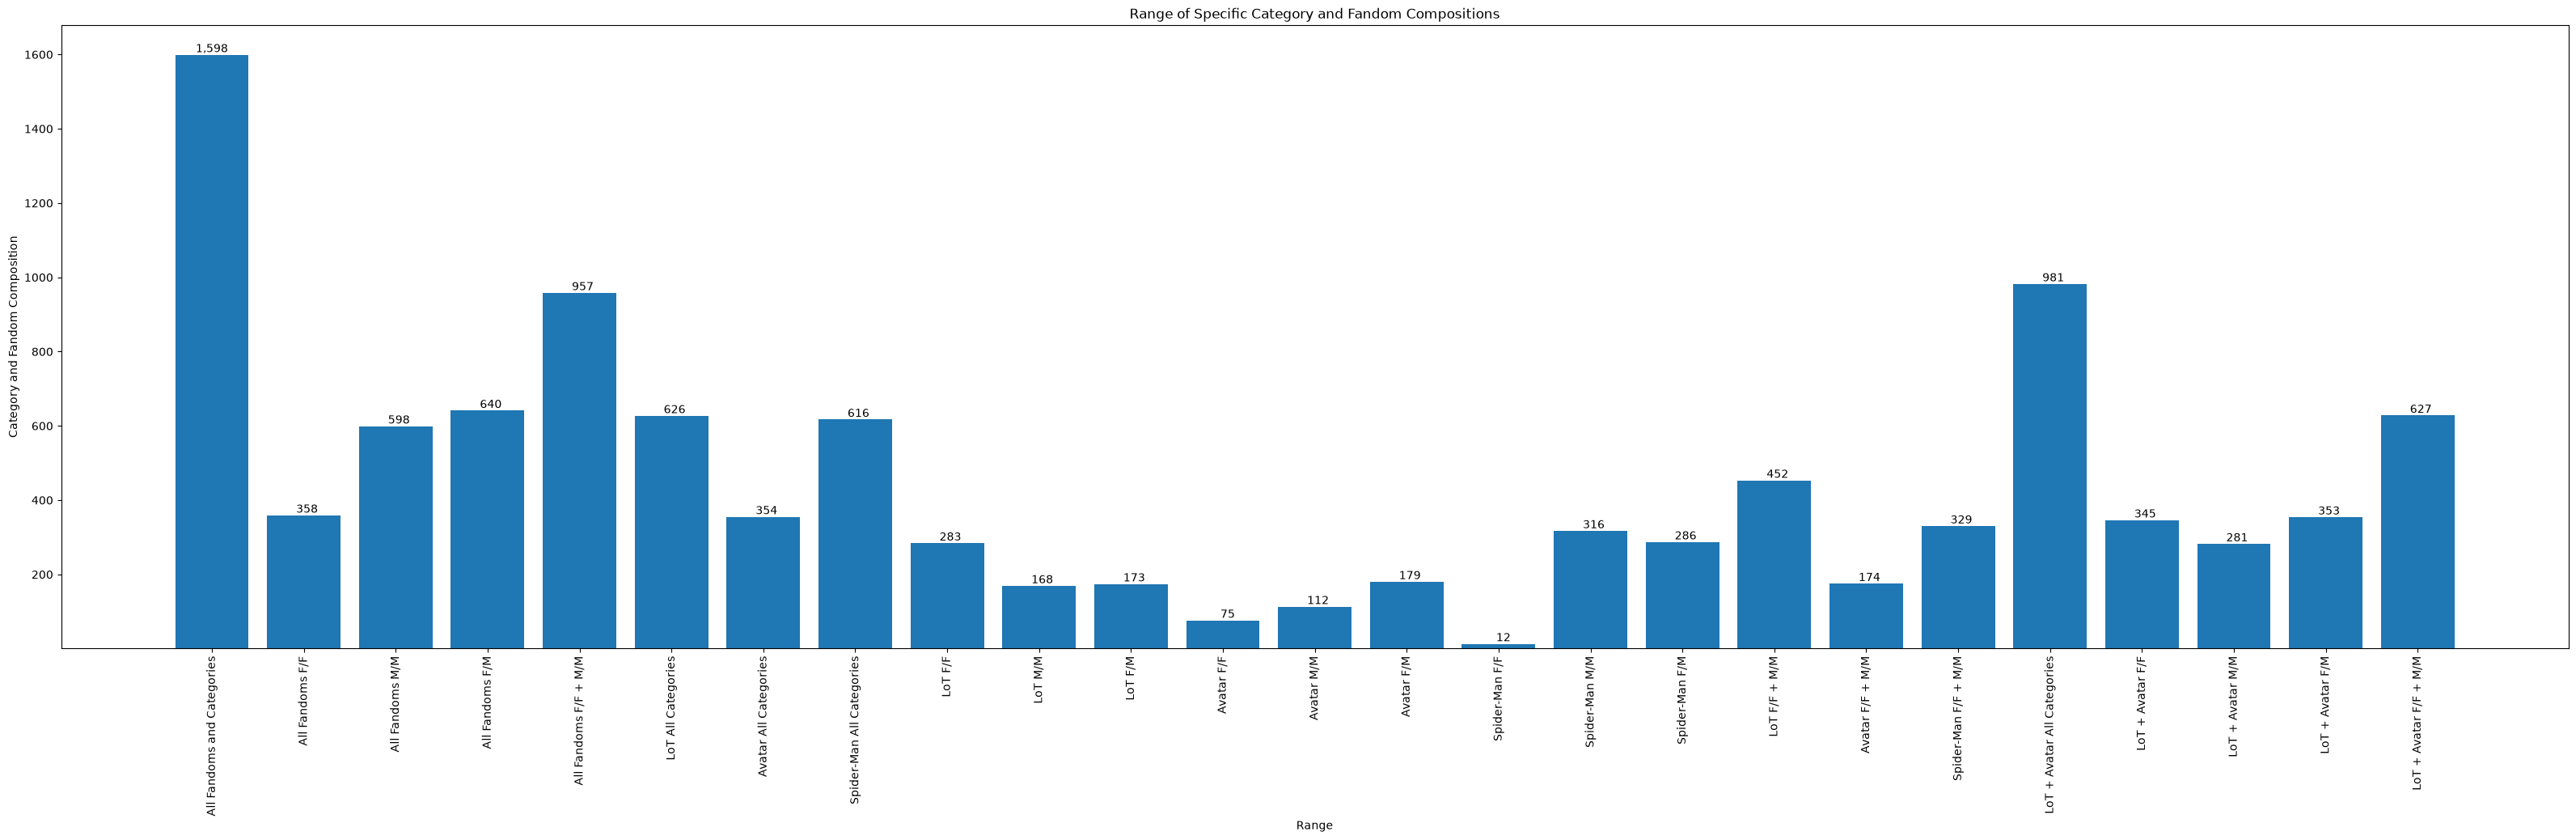

In [17]:
# Plot a horizontal bar plot of the range
fig, ax = plt.subplots(figsize=(40, 10))
bar_container = ax.bar(dict_names, ranges, bottom=mins)
ax.tick_params(axis='x', labelrotation=90)
ax.set(ylabel='Category and Fandom Composition', xlabel='Range', title='Range of Specific Category and Fandom Compositions')
ax.bar_label(bar_container, fmt='{:5,.0f}', rotation=0)
plt.show()

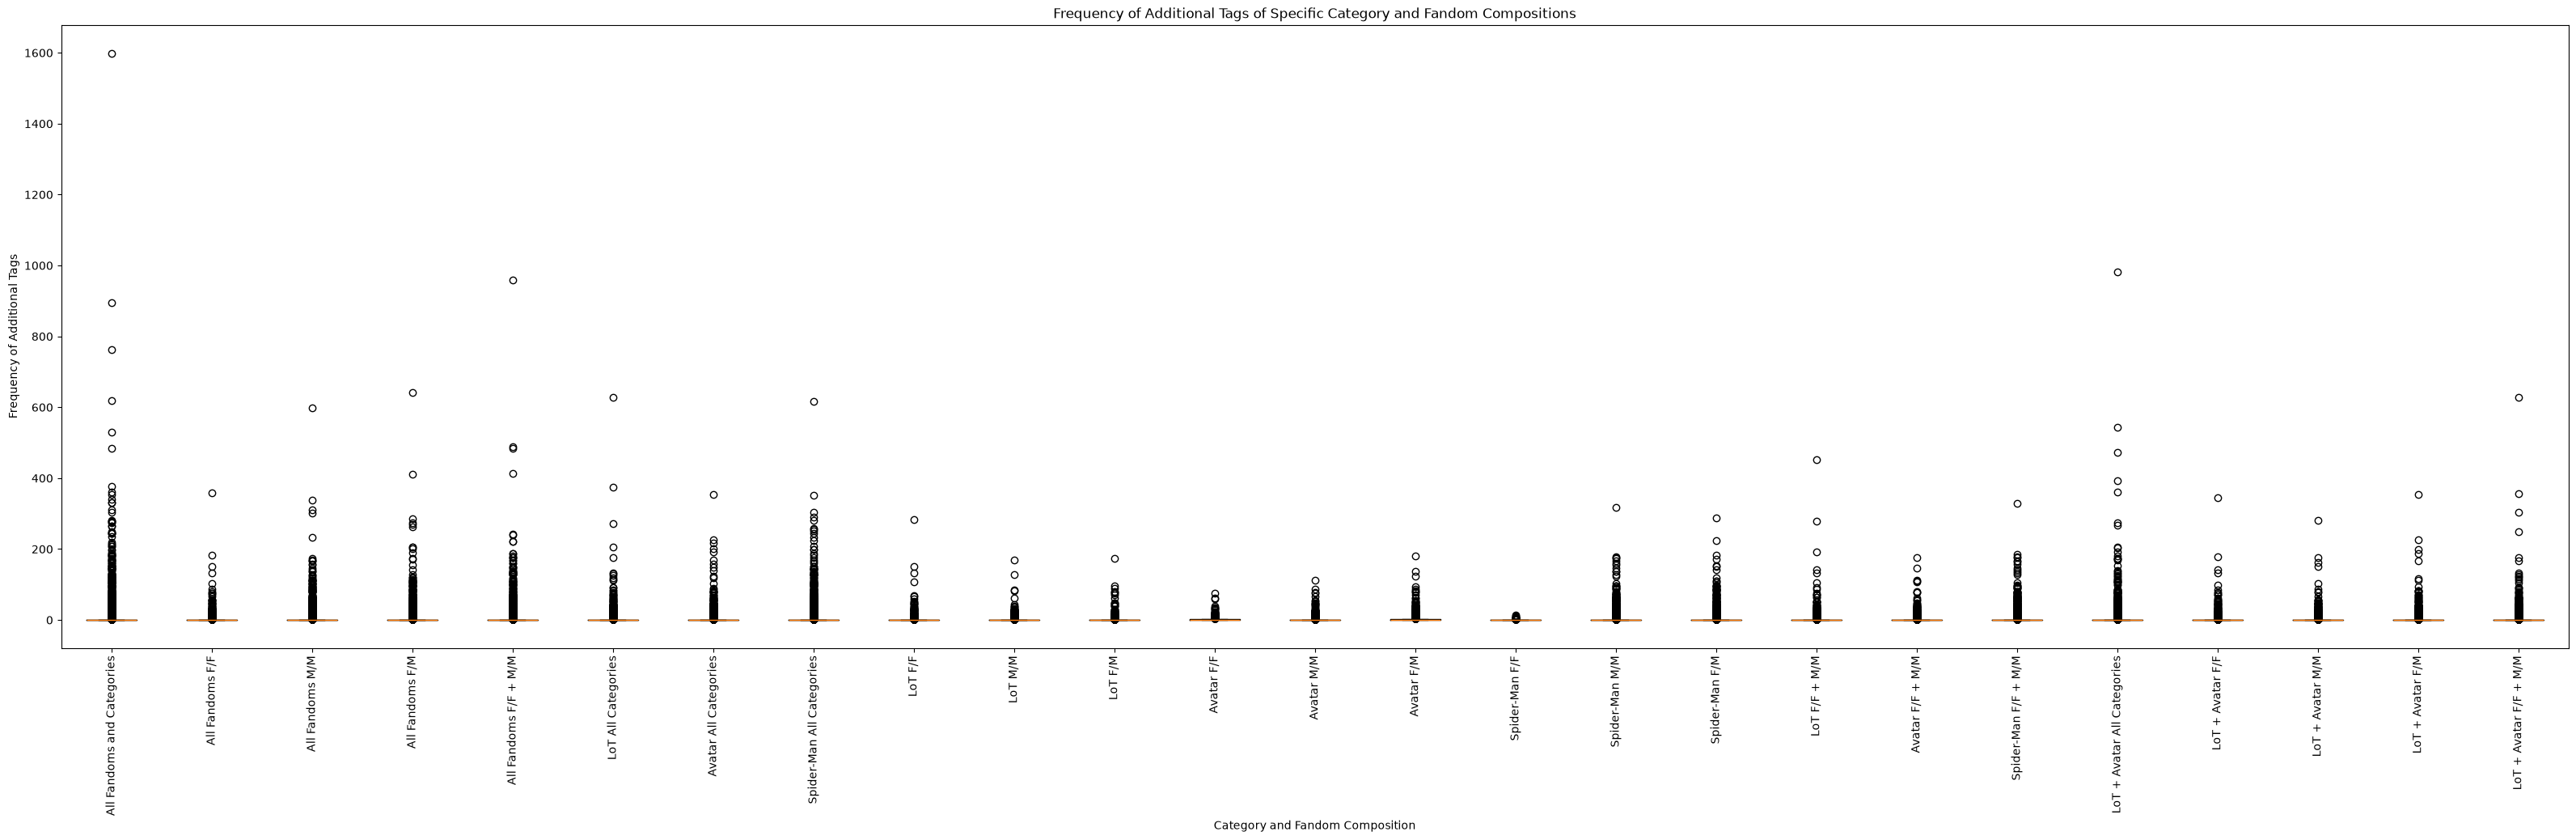

In [18]:
# Plot vertical boxplots of the frequency of additional tags
fig, ax = plt.subplots(figsize=(40, 10))
bar_container = ax.boxplot(dict_of_lists.values(), tick_labels=dict_of_lists.keys())
ax.tick_params(axis='x', labelrotation=90)
ax.set(ylabel='Frequency of Additional Tags', xlabel='Category and Fandom Composition', title='Frequency of Additional Tags of Specific Category and Fandom Compositions')
plt.show()

## 3. Saving DataFrames as CSV Files

In [19]:
# Save the df_main DataFrame as a CSV file
df_main.write_csv('data/additional_tags_freq.csv')
# Save the df_descriptive_stats DataFrame as a CSV file
df_descriptive_stats.write_csv('data/descriptive_stats.csv')